In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
pd.set_option('display.width',800)
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',800)

# pipeline function

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

def impute_and_normalize_data(data, target_cols):
    data_clean_before_imputation = data
    data_clean_before_imputation.reset_index(drop=True, inplace=True)
    targets = data_clean_before_imputation[target_cols]

    data_clean_before_imputation = data_clean_before_imputation.drop(target_cols, axis=1)

    # Separate quantitative and qualitative columns
    quantitative_columns = data_clean_before_imputation.select_dtypes(include=['int64', 'float64']).columns
    qualitative_columns = data_clean_before_imputation.select_dtypes(include=['object']).columns

    # Normalize and impute missing values in quantitative columns
    quantitative_data = data_clean_before_imputation[quantitative_columns]
    scaler = StandardScaler()
    quantitative_data_normalized = pd.DataFrame(scaler.fit_transform(quantitative_data), columns=quantitative_columns)
    imputer = KNNImputer(n_neighbors=5)
    quantitative_data_imputed_normalized = imputer.fit_transform(quantitative_data_normalized)
    quantitative_data_imputed = pd.DataFrame(scaler.inverse_transform(quantitative_data_imputed_normalized), columns=quantitative_columns)

    # Combine imputed quantitative columns and qualitative columns
    data_imputed = pd.concat([quantitative_data_imputed.reset_index(drop=True), data_clean_before_imputation[qualitative_columns].reset_index(drop=True)], axis=1)

    # Add the target columns back and remove rows where the targets are missing
    for col in target_cols:
        data_imputed[col] = targets[col]

    data_imputed = data_imputed.dropna(subset=target_cols)

    return data_imputed

In [120]:
%matplotlib inline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, TransformerMixin
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

class ShiftToPositive(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.min_ = pd.DataFrame(X).min()
        return self

    def transform(self, X):
        X_shifted = pd.DataFrame(X) - self.min_ + 1
        if np.any(np.isnan(X_shifted)) or np.any(np.isinf(X_shifted)):
            raise ValueError('NaN or infinity produced in ShiftToPositive transformation')
        return X_shifted.values


class SignedLogTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_transformed = np.sign(X) * np.log1p(np.abs(X))
        if np.any(np.isnan(X_transformed)) or np.any(np.isinf(X_transformed)):
            raise ValueError('NaN or infinity produced in signed logarithm transformation')
        return X_transformed


def plot_hist_before_after_transformation(X_train, col_name, transformer):
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    sns.histplot(X_train[col_name], kde=True)
    plt.title(f'Before Transformation - {col_name}')

    X_train_transformed = transformer.fit_transform(X_train[[col_name]])

    plt.subplot(1, 2, 2)
    sns.histplot(X_train_transformed, kde=True)
    plt.title(f'After Transformation - {col_name}')

    plt.tight_layout()
    plt.show()

def run_modeling_pipeline(df, target_col, show_graphs=True, random_seed=42, ridge_alpha=np.logspace(-3, 3, 7), lasso_alpha=np.logspace(-3, 3, 7), tol=[1e-3, 1e-4, 1e-5], rf_max_depth=[8,10], rf_min_samples_split=[2,3], rf_min_samples_leaf=[1,3], rf_ccp_alpha=[1e-4, 1e-5, 1e-6], gbr_n_estimators=[100, 200, 300], gbr_learning_rate=[0.01, 0.1, 1], gbr_max_depth=[3, 4, 5], gbr_min_samples_split=[2, 3, 4], gbr_min_samples_leaf=[1, 2, 3], ridge_max_iter=10000, lasso_max_iter=10000):
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(include=[object, pd.Categorical]).columns.tolist()

    shifter = ShiftToPositive()
    log_transformer = SignedLogTransformer()

    if show_graphs:
        for col_name in num_cols:
            plot_hist_before_after_transformation(X_train, col_name, Pipeline(steps=[("shifter", shifter), ("log_transformer", log_transformer)]))

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[("shifter", shifter), ("log_transformer", log_transformer), ("scaler", MinMaxScaler())]), num_cols),
            ("cat", OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ]
    )

    pipe_ridge = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor",  Ridge(max_iter=ridge_max_iter)),
        ]
    )

    pipe_lasso = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", Lasso(max_iter=lasso_max_iter)),
        ]
    )


    pipe_rf = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", RandomForestRegressor()),
        ]
    )

    pipe_gbr = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("regressor", GradientBoostingRegressor(random_state=random_seed)),
        ]
    )

    param_grid_ridge = {
        "regressor__alpha": ridge_alpha,
        "regressor__tol": tol,
    }

    param_grid_lasso = {
        "regressor__alpha": lasso_alpha,
        "regressor__tol": tol,
    }

    param_grid_rf = {
        "regressor__max_depth": rf_max_depth,
        "regressor__min_samples_split": rf_min_samples_split,
        "regressor__min_samples_leaf": rf_min_samples_leaf,
        "regressor__ccp_alpha": rf_ccp_alpha,
    } 

    param_grid_gbr = {
        "regressor__n_estimators": gbr_n_estimators,
        "regressor__learning_rate": gbr_learning_rate,
        "regressor__max_depth": gbr_max_depth,
        "regressor__min_samples_split": gbr_min_samples_split,
        "regressor__min_samples_leaf": gbr_min_samples_leaf,
    }
  
    grid_search_ridge = GridSearchCV(pipe_ridge, param_grid_ridge, cv=5, scoring="r2")
    grid_search_lasso = GridSearchCV(pipe_lasso, param_grid_lasso, cv=5, scoring="r2")
    grid_search_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=5, scoring="r2")
    grid_search_gbr = GridSearchCV(pipe_gbr, param_grid_gbr, cv=5, scoring="r2")

    grid_search_ridge.fit(X_train, y_train)
    grid_search_lasso.fit(X_train, y_train)
    grid_search_rf.fit(X_train, y_train)
    grid_search_gbr.fit(X_train, y_train)
    
    print("Ridge - Best parameters: ", grid_search_ridge.best_params_)
    print("Ridge - Best cross-validation score (R2): ", grid_search_ridge.best_score_)
    print("Lasso - Best parameters: ", grid_search_lasso.best_params_)
    print("Lasso - Best cross-validation score (R2): ", grid_search_lasso.best_score_)
    print("RandomForestRegressor - Best parameters: ", grid_search_rf.best_params_)
    print("RandomForestRegressor - Best cross-validation score (R2): ", grid_search_rf.best_score_)
    print("GradientBoostingRegressor - Best parameters: ", grid_search_gbr.best_params_)
    print("GradientBoostingRegressor - Best cross-validation score (R2): ", grid_search_gbr.best_score_)
    
    return grid_search_ridge, grid_search_lasso, grid_search_rf, grid_search_gbr, X_train, X_test, y_train, y_test


In [5]:
from sklearn.metrics import mean_squared_error

# Evaluation des modèles sur le train set et test set
def eval_model(grid_search, X_train, y_train, X_test, y_test, model_name):
    print(f'{model_name} - Meilleurs paramètres trouvés : {grid_search.best_params_}')
    print(f'{model_name} - Meilleur score de validation croisée (R2) : {grid_search.best_score_}')
    
    y_train_pred = grid_search.predict(X_train)
    y_test_pred = grid_search.predict(X_test)
    
    train_score = grid_search.score(X_train, y_train)
    test_score = grid_search.score(X_test, y_test)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    
    print(f'{model_name} - Score (R2) sur le train set: {train_score}')
    print(f'{model_name} - Score (R2) sur le test set: {test_score}\n')
    print(f'{model_name} - MSE sur le train set: {train_mse}')
    print(f'{model_name} - MSE sur le test set: {test_mse}\n')

In [58]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.colors import LinearSegmentedColormap

def display_summary(grid_searches, model_names, X_train, y_train, X_test, y_test):
    results = []

    def eval_model(grid_search, X_train, y_train, X_test, y_test, model_name):

        y_train_pred = grid_search.predict(X_train)
        y_test_pred = grid_search.predict(X_test)

        train_score = grid_search.score(X_train, y_train)
        test_score = grid_search.score(X_test, y_test)

        train_mse = mean_squared_error(y_train, y_train_pred)
        test_mse = mean_squared_error(y_test, y_test_pred)

        train_rmse = np.sqrt(train_mse)
        test_rmse = np.sqrt(test_mse)

        train_mae = mean_absolute_error(y_train, y_train_pred)
        test_mae = mean_absolute_error(y_test, y_test_pred)

        results.append({'Model': model_name, 
                        'Best Params': grid_search.best_params_,
                        'Best Cross-Val Score (R2)': grid_search.best_score_,
                        'Train Score (R2)': train_score,
                        'Test Score (R2)': test_score,
                        'Train MSE': train_mse,
                        'Test MSE': test_mse,
                        'Train RMSE': train_rmse,
                        'Test RMSE': test_rmse,
                        'Train MAE': train_mae,
                        'Test MAE': test_mae})

    for grid_search, model_name in zip(grid_searches, model_names):
        eval_model(grid_search, X_train, y_train, X_test, y_test, model_name)

    df_results = pd.DataFrame(results)

    def background_gradient(s, cmap='PuBu', low=0, high=0):
        is_max = s == s.max()
        rng = s.max() - s.min()
        norm = mcolors.Normalize(s.min() - (rng * low),
                                s.max() + (rng * high))
        normed = norm(s.values)
        c = [mcolors.rgb2hex(x) for x in plt.cm.get_cmap(cmap)(normed)]
        color_background = ['background-color: %s' % color for color in c]
        color_text = ['color: white' if v else 'color: black' for v in is_max]
        return [f'{cb}; {ct}' for cb, ct in zip(color_background, color_text)]

    def highlight_min(s, cmap='autumn_r', low=0, high=0):  # note the '_r' at the end of the colormap name
        is_min = s == s.min()
        rng = s.max() - s.min()
        norm = mcolors.Normalize(s.min() - (rng * low),
                                s.max() + (rng * high))
        normed = norm(s.values)
        # create a colormap from pink to orange
        cmap = LinearSegmentedColormap.from_list("mycmap", ['#b0285f', 'pink'])
        c = [mcolors.rgb2hex(x) for x in cmap(normed)]  # apply colormap to normed values
        color_background = ['background-color: %s' % color for color in c]
        color_text = ['color: white' if v else 'color: black' for v in is_min]
        return [f'{cb}; {ct}' for cb, ct in zip(color_background, color_text)]

    return df_results.style.apply(background_gradient, subset=['Best Cross-Val Score (R2)', 'Train Score (R2)', 'Test Score (R2)']).apply(highlight_min, subset=['Train MSE', 'Test MSE', 'Train RMSE', 'Test RMSE', 'Train MAE', 'Test MAE'])


## Feature importance

In [7]:
def feature_importance(df, target_col):
    """This function is used to calculate and visualize the importance of each feature in predicting the target variable using 
    a RandomForestRegressor model. It takes as input a DataFrame and the name of the target column. It one-hot encodes the 
    categorical columns, splits the data into training and testing sets, and fits a RandomForestRegressor model to the 
    training data. It then calculates the importance of each feature, sorts them in descending order of importance, and plots 
    a bar chart of the feature importances. This function is useful for understanding which features are most influential in 
    the model's predictions."""

    
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import train_test_split
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np
    import seaborn as sns
    
    default_font_size = plt.rcParams['font.size']
    default_axes_labelsize = plt.rcParams['axes.labelsize']

    X = df.drop(target_col, axis=1)
    y = df[target_col]

    cat_cols = X.select_dtypes(include=[object, pd.Categorical]).columns.tolist()

    # One-hot encode categorical columns
    X_encoded = pd.get_dummies(X, columns=cat_cols)

    # Split the data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

    # Fit the model
    model = RandomForestRegressor()
    model.fit(X_train, y_train)

    # Get feature importances
    importances = model.feature_importances_

    # Convert feature importances into a pandas DataFrame
    importances_df = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': importances
    })

    # Sort DataFrame by importance
    importances_df = importances_df.sort_values(by='Importance', ascending=False)

    # Create a color palette
    palette = sns.color_palette("pastel", len(importances_df))

    # Update default text sizes
    plt.rcParams.update({'font.size': 18, 'axes.labelsize': 14})

    # Plot feature importances
    plt.figure(figsize=(20, 12))
    sns.barplot(x="Importance", y="Feature", data=importances_df, palette=palette)
    plt.xlabel('Importance')
    plt.title('Feature importances')
    plt.show()
    
        
    plt.rcParams.update({'font.size': default_font_size, 'axes.labelsize': default_axes_labelsize}) # Restaurer les paramètres


### SHAP

SHAP (SHapley Additive exPlanations),  la méthode SHAP donne une vue globale de l'importance des caractéristiques pour l'ensemble du modèle 

In [8]:
!pip install shap
import shap
import xgboost
import pandas as pd

def calculate_shap_values(X_train, y_train):
    # One-hot encode the training data
    X_train_encoded = pd.get_dummies(X_train)

    # Convert data into a format that XGBoost can handle
    dtrain = xgboost.DMatrix(X_train_encoded, label=y_train)

    # Fit an XGBoost model
    model = xgboost.train({"learning_rate": 0.01}, dtrain, 100)

    # Explain the model's predictions using SHAP
    explainer = shap.Explainer(model)
    shap_values = explainer.shap_values(X_train_encoded)

    return explainer, shap_values, X_train_encoded

def plot_shap_summary(explainer, shap_values, X_train):
    # One-hot encode the training data
    X_train_encoded = pd.get_dummies(X_train)

    # Summarize the effects of all the features
    shap.summary_plot(shap_values, X_train_encoded)

# Usage :
# explainer, shap_values, X_train_encoded = calculate_shap_values(X_train, y_train)
# plot_shap_summary(explainer, shap_values, X_train_encoded)


# Dataset immeubles consommation énergie et émission CO2

In [9]:
data = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

## suppression des outliers et valeurs aberrantes, colonnes ayant trop de valeurs manquantes et data non concernées

In [10]:
data.columns

Index(['OSEBuildingID', 'DataYear', 'BuildingType', 'PrimaryPropertyType', 'PropertyName', 'Address', 'City', 'State', 'ZipCode', 'TaxParcelIdentificationNumber', 'CouncilDistrictCode', 'Neighborhood', 'Latitude', 'Longitude', 'YearBuilt', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'ListOfAllPropertyUseTypes', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'YearsENERGYSTARCertified', 'ENERGYSTARScore', 'SiteEUI(kBtu/sf)', 'SiteEUIWN(kBtu/sf)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'SiteEnergyUse(kBtu)', 'SiteEnergyUseWN(kBtu)', 'SteamUse(kBtu)', 'Electricity(kWh)',
       'Electricity(kBtu)', 'NaturalGas(therms)', 'NaturalGas(kBtu)', 'DefaultData', 'Comments', 'ComplianceStatus', 'Outlier', 'TotalGHGEmissions', 'GHGEmissionsIntensity'],
      dtype='object')

In [11]:
data_clean = data[~data['BuildingType'].str.contains("Multifamily")] #Filtre sur Building Type pour garder les bâtiments non destinés à l'habitation, 
data_clean = data_clean[~data_clean['PrimaryPropertyType'].str.contains("Multifamily")] 
data_clean.shape

(1665, 46)

In [12]:
data_clean = data_clean[data_clean["Outlier"] != "High outlier"] #suppression des lignes où "Outlier" prend la valeur High

# Suppression de la colonne "Outlier"
data_clean = data_clean.drop(columns=["Outlier"])

print(data_clean.shape)


(1663, 45)


In [13]:
def is_numeric(value):
    return isinstance(value, (int, float, np.number))

def replace_negative_except_columns(x, columns):
    if x.name in columns:
        return x
    return x.apply(lambda v: np.nan if (is_numeric(v) and v < 0) else v) 
# Remplace les valeurs négatives par NaN, sauf pour les colonnes spécifiées
columns_to_keep = ["Longitude", "Latitude", "ZipCode"]
data_clean = data_clean.apply(lambda x: replace_negative_except_columns(x, columns_to_keep))

In [14]:
data.shape

(3376, 46)

In [15]:
# Suppression des données non compliant
data_clean = data_clean[~data_clean['ComplianceStatus'].isin(['Error - Correct Default Data', 'Missing Data', 'Non-Compliant'])]
data_clean.drop(columns=['ComplianceStatus'], inplace=True)

In [16]:
def find_missing_data(df):
    missing_data = df.isnull().sum()
    missing_percent = missing_data / len(df) * 100
    missing_over_80 = missing_percent[missing_percent > 20]
    
    return missing_over_80

missing_over_80 = find_missing_data(data_clean)
print("Colonnes avec plus de 30% de valeurs manquantes :")
print(missing_over_80)

Colonnes avec plus de 30% de valeurs manquantes :
SecondLargestPropertyUseType        45.601552
SecondLargestPropertyUseTypeGFA     45.601552
ThirdLargestPropertyUseType         77.554981
ThirdLargestPropertyUseTypeGFA      77.554981
YearsENERGYSTARCertified            93.725744
ENERGYSTARScore                     35.575679
Comments                           100.000000
dtype: float64


In [17]:
data_clean = data_clean[data_clean.columns[data_clean.isna().sum()/data_clean.shape[0]<0.3]]

In [18]:
data_clean.isna().sum()

OSEBuildingID                     0
DataYear                          0
BuildingType                      0
PrimaryPropertyType               0
PropertyName                      0
Address                           0
City                              0
State                             0
ZipCode                          13
TaxParcelIdentificationNumber     0
CouncilDistrictCode               0
Neighborhood                      0
Latitude                          0
Longitude                         0
YearBuilt                         0
NumberofBuildings                 0
NumberofFloors                    0
PropertyGFATotal                  0
PropertyGFAParking                0
PropertyGFABuilding(s)            0
ListOfAllPropertyUseTypes         0
LargestPropertyUseType            4
LargestPropertyUseTypeGFA         4
SiteEUI(kBtu/sf)                  0
SiteEUIWN(kBtu/sf)                1
SourceEUI(kBtu/sf)                0
SourceEUIWN(kBtu/sf)              1
SiteEnergyUse(kBtu)         

In [19]:
data_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1546 entries, 0 to 3375
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   OSEBuildingID                  1546 non-null   int64  
 1   DataYear                       1546 non-null   int64  
 2   BuildingType                   1546 non-null   object 
 3   PrimaryPropertyType            1546 non-null   object 
 4   PropertyName                   1546 non-null   object 
 5   Address                        1546 non-null   object 
 6   City                           1546 non-null   object 
 7   State                          1546 non-null   object 
 8   ZipCode                        1533 non-null   float64
 9   TaxParcelIdentificationNumber  1546 non-null   object 
 10  CouncilDistrictCode            1546 non-null   int64  
 11  Neighborhood                   1546 non-null   object 
 12  Latitude                       1546 non-null   f

# choix des colonnes gardées

In [20]:
data_clean.shape

(1546, 37)

In [21]:
data_clean_before_imputation = data_clean[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","SiteEnergyUse(kBtu)"]]
data_clean_before_imputation.shape

(1546, 8)

## apercu avant imputation

In [22]:
data_clean_before_imputation_nan = data_clean_before_imputation.isna().sum().sort_values(ascending=False)
data_clean_before_imputation_nan

TotalGHGEmissions         1
NumberofBuildings         0
NumberofFloors            0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
PrimaryPropertyType       0
SiteEnergyUse(kBtu)       0
dtype: int64

In [23]:
data_clean_before_imputation_nan.isna().sum()

0

In [24]:
data_clean_before_imputation.shape

(1546, 8)

In [25]:
data_clean_before_imputation.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12,1927,0,88434,Hotel,249.98,7226362.5
1,1.0,11,1996,15064,88502,Hotel,295.86,8387933.0
2,1.0,41,1969,196718,759392,Hotel,2089.28,72587024.0
3,1.0,10,1926,0,61320,Hotel,286.43,6794584.0
4,1.0,18,1980,62000,113580,Hotel,505.01,14172606.0


## imputation

In [26]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_imputed = impute_and_normalize_data(data_clean_before_imputation, target_cols)
data_imputed.head()

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,249.98,7226362.5
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,295.86,8387933.0
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,2089.28,72587024.0
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,286.43,6794584.0
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,505.01,14172606.0


## dataset pour la modélisations consommation d'energie

In [27]:
data_modelisation_conso = data_imputed[["NumberofBuildings", "NumberofFloors", "PrimaryPropertyType","YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "SiteEnergyUse(kBtu)"]]


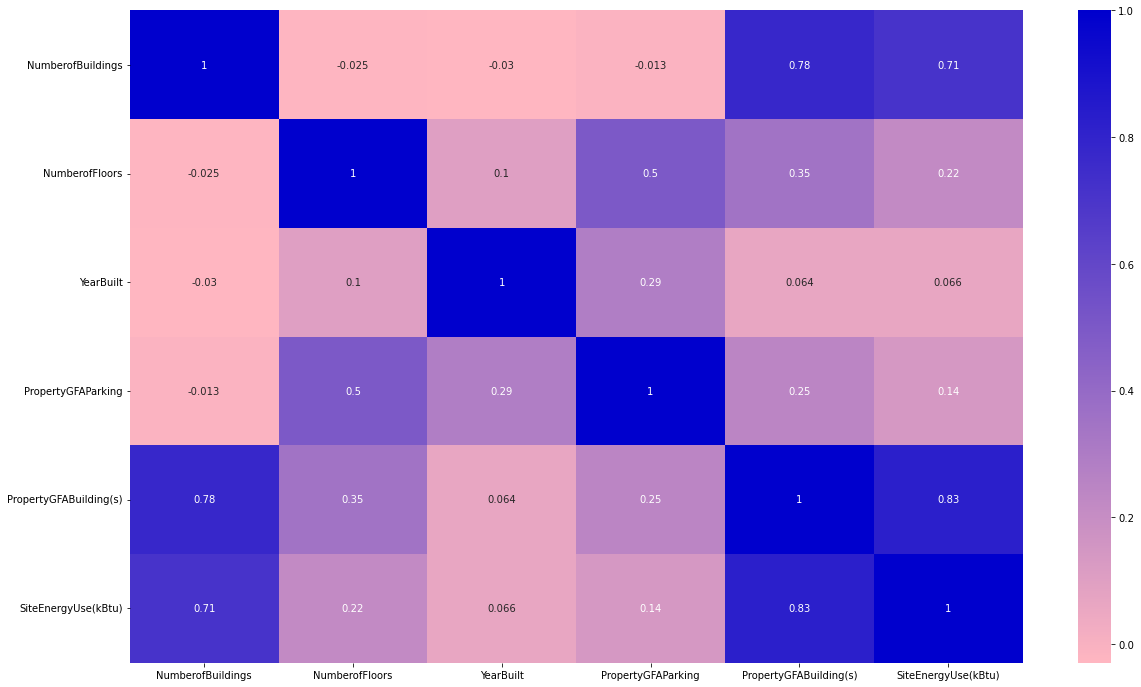

In [35]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(data_modelisation_conso.corr(), annot=True, cmap=cmap)
plt.show()


### modélisation de la prédiction consommation énergie

In [29]:
data_modelisation_conso.isna().sum()

NumberofBuildings         0
NumberofFloors            0
PrimaryPropertyType       0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
SiteEnergyUse(kBtu)       0
dtype: int64

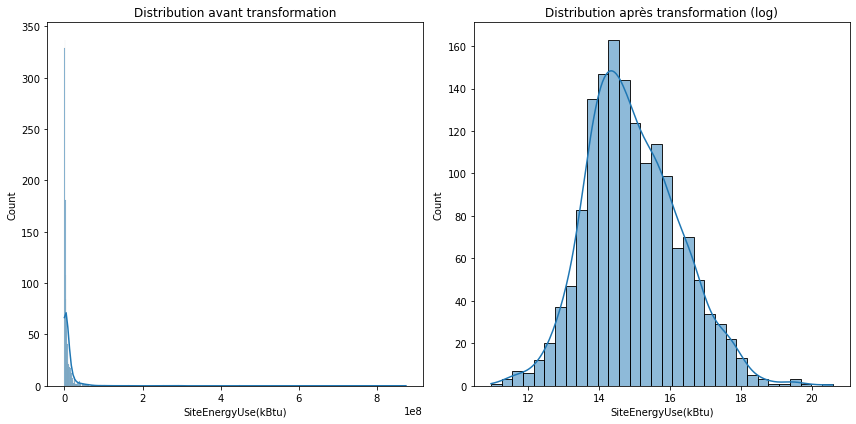

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_conso["SiteEnergyUse(kBtu)"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_conso_log = np.log1p(data_modelisation_conso["SiteEnergyUse(kBtu)"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_conso_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_conso_modified = data_modelisation_conso.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_conso_modified["SiteEnergyUse(kBtu)"] = np.log1p(data_modelisation_conso_modified["SiteEnergyUse(kBtu)"])

data_modelisation_conso = data_modelisation_conso_modified



In [37]:
grid_search_ridge_before_fe_conso, grid_search_lasso_before_fe_conso, grid_search_rf_before_fe_conso, grid_search_gbr_before_fe_conso, X_train_before_fe_conso, X_test_before_fe_conso, y_train_before_fe_conso, y_test_before_fe_conso = run_modeling_pipeline(df=data_modelisation_conso, target_col="SiteEnergyUse(kBtu)", show_graphs=False, random_seed=22, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[0.01], ridge_max_iter=10000, lasso_max_iter=10000)


Ridge - Best parameters:  {'regressor__alpha': 1.0, 'regressor__tol': 0.01}
Ridge - Best cross-validation score (R2):  0.6229912224938565
Lasso - Best parameters:  {'regressor__alpha': 0.001, 'regressor__tol': 0.01}
Lasso - Best cross-validation score (R2):  0.6009699272002088
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 0.0001, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}
RandomForestRegressor - Best cross-validation score (R2):  0.7073005888033842
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
GradientBoostingRegressor - Best cross-validation score (R2):  0.7243260690735147


In [31]:
best_score_ridge_before_fe_conso = grid_search_ridge_before_fe_conso.best_score_
best_score_lasso_before_fe_conso = grid_search_lasso_before_fe_conso.best_score_
best_score_rf_before_fe_conso = grid_search_rf_before_fe_conso.best_score_
best_score_gbr_before_fe_conso = grid_search_gbr_before_fe_conso.best_score_

best_params_ridge_before_fe_conso = grid_search_ridge_before_fe_conso.best_params_
best_params_lasso_before_fe_conso = grid_search_lasso_before_fe_conso.best_params_
best_params_rf_before_fe_conso = grid_search_rf_before_fe_conso.best_params_
best_params_gbr_before_fe_conso = grid_search_gbr_before_fe_conso.best_params_



<div style="background-color:orange; color:dark;"> 
    <strong>évaluer les performances de chaque modèle sur l'ensemble d'entraînement </strong>
    <br>Calcul du score R2 et l'erreur quadratique moyenne (MSE) sur l'ensemble d'entraînement pour chaque modèle, comparaison aux scores sur l'ensemble de test<br>
</div>


le score R2 donne une indication de la proportion de variance expliquée par le modèle, le MSE quantifie l'erreur résiduelle en termes de distance au carré des prédictions du modèle par rapport aux valeurs réelles.

# 🔴RESULTS 1 avant feature engineering -- CONSO

In [59]:
summary_before_fe_conso = display_summary([grid_search_ridge_before_fe_conso, grid_search_lasso_before_fe_conso, grid_search_rf_before_fe_conso, grid_search_gbr_before_fe_conso], 
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_before_fe_conso, y_train_before_fe_conso, X_test_before_fe_conso, y_test_before_fe_conso)
summary_before_fe_conso

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 1.0, 'regressor__tol': 0.01}",0.622991,0.696974,0.687599,0.524378,0.525505,0.724139,0.724918,0.532784,0.541797
1,Lasso,"{'regressor__alpha': 0.001, 'regressor__tol': 0.01}",0.600970,0.709334,0.705972,0.502990,0.494598,0.709218,0.703277,0.509159,0.527216
2,RandomForestRegressor,"{'regressor__ccp_alpha': 0.0001, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}",0.707301,0.874747,0.666108,0.216748,0.561656,0.465562,0.749437,0.353735,0.568120
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 3, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}",0.724326,0.803987,0.703498,0.339196,0.498760,0.582405,0.706229,0.433202,0.538693


#### features importance

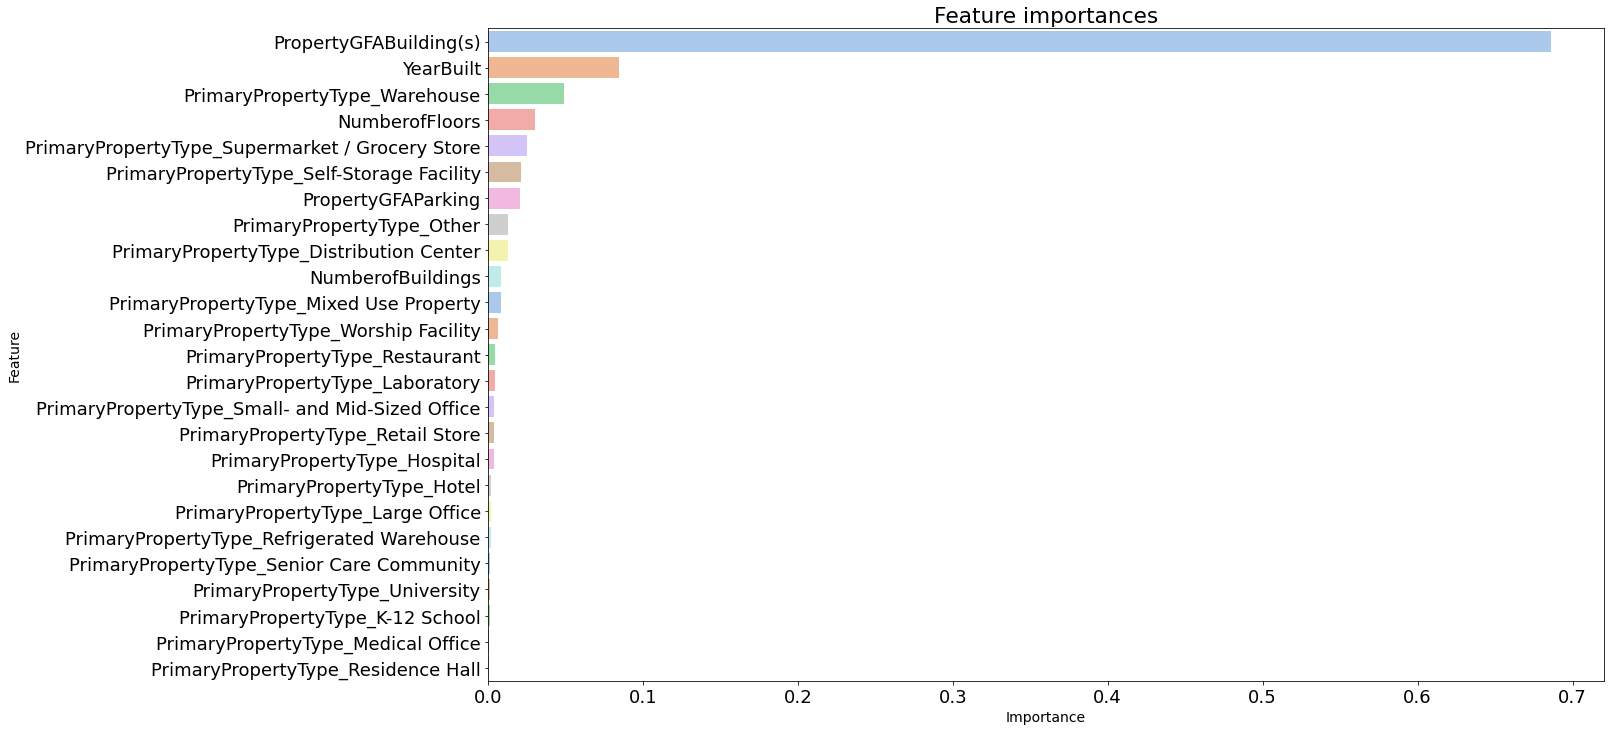

In [42]:
feature_importance_before_fe_conso =feature_importance(df=data_modelisation_conso, target_col="SiteEnergyUse(kBtu)")
feature_importance_before_fe_conso

# Feature engineering energy use type

## add energy type and compliance status columns

In [43]:
df_feature1 = data_clean[["NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","SteamUse(kBtu)","NaturalGas(kBtu)","Electricity(kBtu)","TotalGHGEmissions","SiteEnergyUse(kBtu)"]]



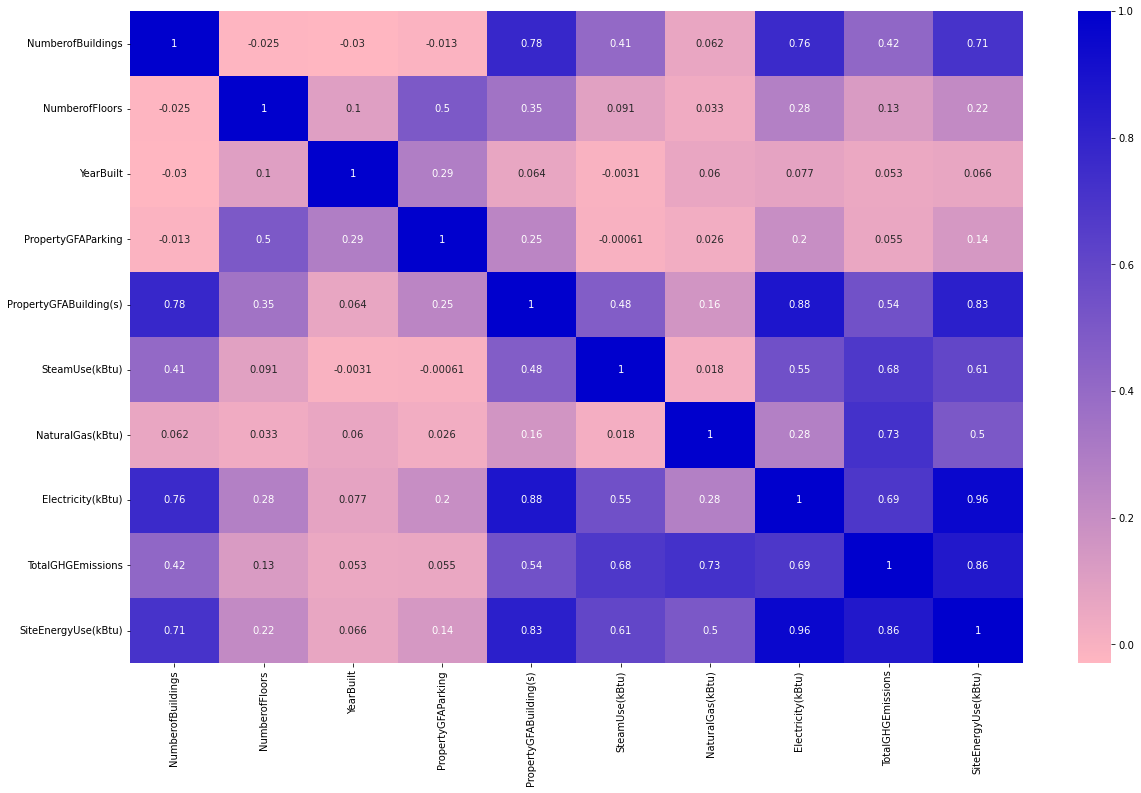

In [44]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(df_feature1.corr(), annot=True, cmap=cmap)
plt.show()


In [45]:
df_feature1.isna().sum()

NumberofBuildings         0
NumberofFloors            0
YearBuilt                 0
PropertyGFAParking        0
PropertyGFABuilding(s)    0
PrimaryPropertyType       0
SteamUse(kBtu)            0
NaturalGas(kBtu)          0
Electricity(kBtu)         1
TotalGHGEmissions         1
SiteEnergyUse(kBtu)       0
dtype: int64

In [46]:
qualitative_cols = df_feature1.select_dtypes(include='object').columns.tolist()

for col in qualitative_cols:
    unique_values = data[col].unique()
    print("\n",col, ": valeurs uniques", len(unique_values),"\n", unique_values)


 PrimaryPropertyType : valeurs uniques 24 
 ['Hotel' 'Other' 'Mid-Rise Multifamily' 'Mixed Use Property' 'K-12 School'
 'University' 'Small- and Mid-Sized Office' 'Self-Storage Facility'
 'Warehouse' 'Large Office' 'Senior Care Community' 'Medical Office'
 'Retail Store' 'Hospital' 'Residence Hall' 'Distribution Center'
 'Worship Facility' 'Low-Rise Multifamily' 'Supermarket / Grocery Store'
 'Laboratory' 'Refrigerated Warehouse' 'Restaurant'
 'High-Rise Multifamily' 'Office']


In [47]:
# Créer des colonnes pour les types d'énergie
df_feature1['HasElectricity'] = df_feature1['Electricity(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1['HasNaturalGas'] = df_feature1['NaturalGas(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1['HasSteam'] = df_feature1['SteamUse(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
df_feature1


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,SteamUse(kBtu),NaturalGas(kBtu),Electricity(kBtu),TotalGHGEmissions,SiteEnergyUse(kBtu),HasElectricity,HasNaturalGas,HasSteam
0,1.0,12,1927,0,88434,Hotel,2003882.00,1.276453e+06,3.946027e+06,249.98,7.226362e+06,oui,oui,oui
1,1.0,11,1996,15064,88502,Hotel,0.00,5.145082e+06,3.242851e+06,295.86,8.387933e+06,oui,oui,non
2,1.0,41,1969,196718,759392,Hotel,21566554.00,1.493800e+06,4.952666e+07,2089.28,7.258702e+07,oui,oui,oui
3,1.0,10,1926,0,61320,Hotel,2214446.25,1.811213e+06,2.768924e+06,286.43,6.794584e+06,oui,oui,oui
4,1.0,18,1980,62000,113580,Hotel,0.00,8.803998e+06,5.368607e+06,505.01,1.417261e+07,oui,oui,non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3370,1.0,1,1982,0,18261,Other,0.00,2.997200e+05,6.323620e+05,20.33,9.320821e+05,oui,oui,non
3372,1.0,1,2004,0,16000,Other,0.00,5.537300e+05,3.965461e+05,32.17,9.502762e+05,oui,oui,non
3373,1.0,1,1974,0,13157,Other,0.00,3.973739e+06,1.792159e+06,223.54,5.765898e+06,oui,oui,non
3374,1.0,1,1989,0,14101,Mixed Use Property,0.00,3.706010e+05,3.488702e+05,22.11,7.194712e+05,oui,oui,non


In [48]:
df_feature1 = df_feature1.drop(['Electricity(kBtu)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)'], axis=1)

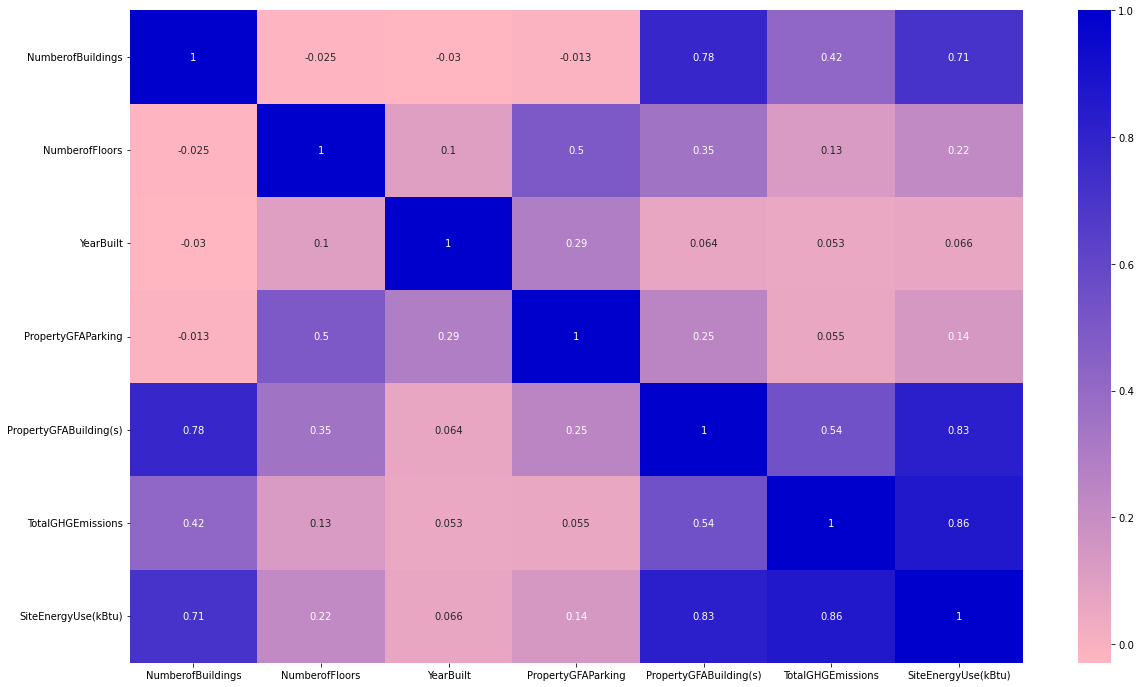

In [49]:
import matplotlib.colors as mcolors

colors = ["#FFB6C1", "#0000CD"]  # LightPink to MediumBlue
cmap = mcolors.LinearSegmentedColormap.from_list("mycmap", colors)

plt.figure(figsize=(20,12))
sns.heatmap(df_feature1.corr(), annot=True, cmap=cmap)
plt.show()

In [50]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_clean_before_imputation2 = df_feature1
data_imputed2 = impute_and_normalize_data(data_clean_before_imputation2, target_cols)
data_imputed2

,NumberofBuildings,NumberofFloors,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),PrimaryPropertyType,HasElectricity,HasNaturalGas,HasSteam,TotalGHGEmissions,SiteEnergyUse(kBtu)
0,1.0,12.0,1927.0,0.0,88434.0,Hotel,oui,oui,oui,249.98,7.226362e+06
1,1.0,11.0,1996.0,15064.0,88502.0,Hotel,oui,oui,non,295.86,8.387933e+06
2,1.0,41.0,1969.0,196718.0,759392.0,Hotel,oui,oui,oui,2089.28,7.258702e+07
3,1.0,10.0,1926.0,0.0,61320.0,Hotel,oui,oui,oui,286.43,6.794584e+06
4,1.0,18.0,1980.0,62000.0,113580.0,Hotel,oui,oui,non,505.01,1.417261e+07
...,...,...,...,...,...,...,...,...,...,...,...
1541,1.0,1.0,1982.0,0.0,18261.0,Other,oui,oui,non,20.33,9.320821e+05
1542,1.0,1.0,2004.0,0.0,16000.0,Other,oui,oui,non,32.17,9.502762e+05
1543,1.0,1.0,1974.0,0.0,13157.0,Other,oui,oui,non,223.54,5.765898e+06
1544,1.0,1.0,1989.0,0.0,14101.0,Mixed Use Property,oui,oui,non,22.11,7.194712e+05


In [51]:
data_imputed2.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1545 entries, 0 to 1545
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NumberofBuildings       1545 non-null   float64
 1   NumberofFloors          1545 non-null   float64
 2   YearBuilt               1545 non-null   float64
 3   PropertyGFAParking      1545 non-null   float64
 4   PropertyGFABuilding(s)  1545 non-null   float64
 5   PrimaryPropertyType     1545 non-null   object 
 6   HasElectricity          1545 non-null   object 
 7   HasNaturalGas           1545 non-null   object 
 8   HasSteam                1545 non-null   object 
 9   TotalGHGEmissions       1545 non-null   float64
 10  SiteEnergyUse(kBtu)     1545 non-null   float64
dtypes: float64(7), object(4)
memory usage: 144.8+ KB


In [106]:
data_modelisation_conso2 = data_imputed2[["NumberofBuildings", "NumberofFloors", "PrimaryPropertyType","YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", 'HasElectricity','HasNaturalGas','HasSteam', 'SiteEnergyUse(kBtu)']]

### modélisation de la prédiction consommation énergie

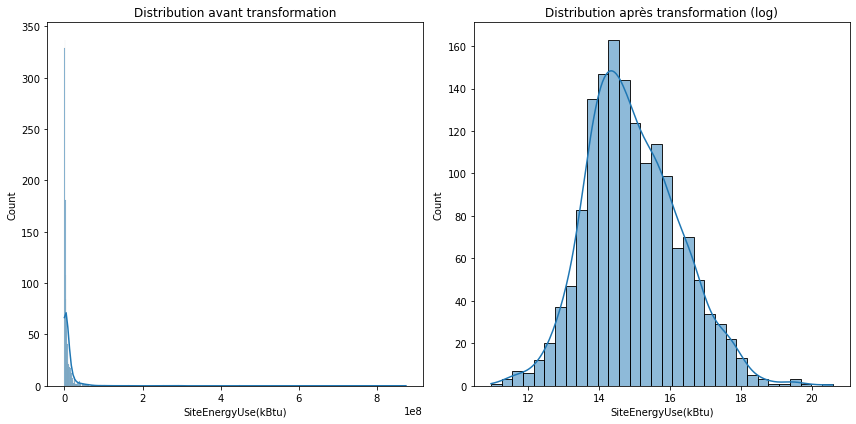

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Afficher la distribution avant la transformation
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(data_modelisation_conso2["SiteEnergyUse(kBtu)"], kde=True)
plt.title("Distribution avant transformation")

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
total_ghg_emissions_log = np.log1p(data_modelisation_conso2["SiteEnergyUse(kBtu)"])

# Afficher la distribution après la transformation
plt.subplot(1, 2, 2)
sns.histplot(total_ghg_emissions_log, kde=True)
plt.title("Distribution après transformation (log)")

plt.tight_layout()
plt.show()


# Copier le dataframe original
data_modelisation_conso2_modified = data_modelisation_conso2.copy()

# Appliquer la transformation log sur la colonne "TotalGHGEmissions"
data_modelisation_conso2_modified["SiteEnergyUse(kBtu)"] = np.log1p(data_modelisation_conso2_modified["SiteEnergyUse(kBtu)"])

data_modelisation_conso2 = data_modelisation_conso2_modified


In [108]:
data_modelisation_conso2.head()

,NumberofBuildings,NumberofFloors,PrimaryPropertyType,YearBuilt,PropertyGFAParking,PropertyGFABuilding(s),HasElectricity,HasNaturalGas,HasSteam,SiteEnergyUse(kBtu)
0,1.0,12.0,Hotel,1927.0,0.0,88434.0,oui,oui,oui,15.793246
1,1.0,11.0,Hotel,1996.0,15064.0,88502.0,oui,oui,non,15.942305
2,1.0,41.0,Hotel,1969.0,196718.0,759392.0,oui,oui,oui,18.100297
3,1.0,10.0,Hotel,1926.0,0.0,61320.0,oui,oui,oui,15.731637
4,1.0,18.0,Hotel,1980.0,62000.0,113580.0,oui,oui,non,16.466822


In [109]:
grid_search_ridge_fe_conso, grid_search_lasso_fe_conso, grid_search_rf_fe_conso, grid_search_gbr_fe_conso, X_train_fe_conso, X_test_fe_conso, y_train_fe_conso, y_test_fe_conso = run_modeling_pipeline(df=data_modelisation_conso2, target_col="SiteEnergyUse(kBtu)", show_graphs=False, random_seed=32, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[1e-3, 1e-4, 1e-5])




Ridge - Best parameters:  {'regressor__alpha': 1.0, 'regressor__tol': 0.001}
Ridge - Best cross-validation score (R2):  0.6397078852974245
Lasso - Best parameters:  {'regressor__alpha': 0.001, 'regressor__tol': 1e-05}
Lasso - Best cross-validation score (R2):  0.6231611494821777
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}
RandomForestRegressor - Best cross-validation score (R2):  0.7060059624768746
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}
GradientBoostingRegressor - Best cross-validation score (R2):  0.7323705749068082


In [110]:
best_score_ridge_fe_conso = grid_search_ridge_fe_conso.best_score_
best_score_lasso_fe_conso = grid_search_lasso_fe_conso.best_score_
best_score_rf_fe_conso = grid_search_rf_fe_conso.best_score_
best_score_gbr_fe_conso = grid_search_gbr_fe_conso.best_score_

best_params_ridge_fe_conso = grid_search_ridge_fe_conso.best_params_
best_params_lasso_fe_conso = grid_search_lasso_fe_conso.best_params_
best_params_rf_fe_conso = grid_search_rf_fe_conso.best_params_
best_params_gbr_fe_conso = grid_search_gbr_fe_conso.best_params_

# 🔴RESULTS 2 après feature engineering 1 -- CONSO

In [111]:
summary = display_summary([grid_search_ridge_fe_conso, grid_search_lasso_fe_conso, grid_search_rf_fe_conso, grid_search_gbr_fe_conso], 
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_fe_conso, y_train_fe_conso, X_test_fe_conso, y_test_fe_conso)
summary

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 1.0, 'regressor__tol': 0.001}",0.639708,0.715098,0.731926,0.481603,0.493399,0.693976,0.702423,0.512617,0.532683
1,Lasso,"{'regressor__alpha': 0.001, 'regressor__tol': 1e-05}",0.623161,0.722658,0.748769,0.468825,0.462398,0.684708,0.679998,0.495058,0.513553
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-05, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}",0.706006,0.879021,0.736204,0.204505,0.485526,0.452223,0.696797,0.341970,0.511691
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 100}",0.732371,0.812210,0.763498,0.317443,0.435290,0.563421,0.659765,0.418807,0.494479


#### features importance

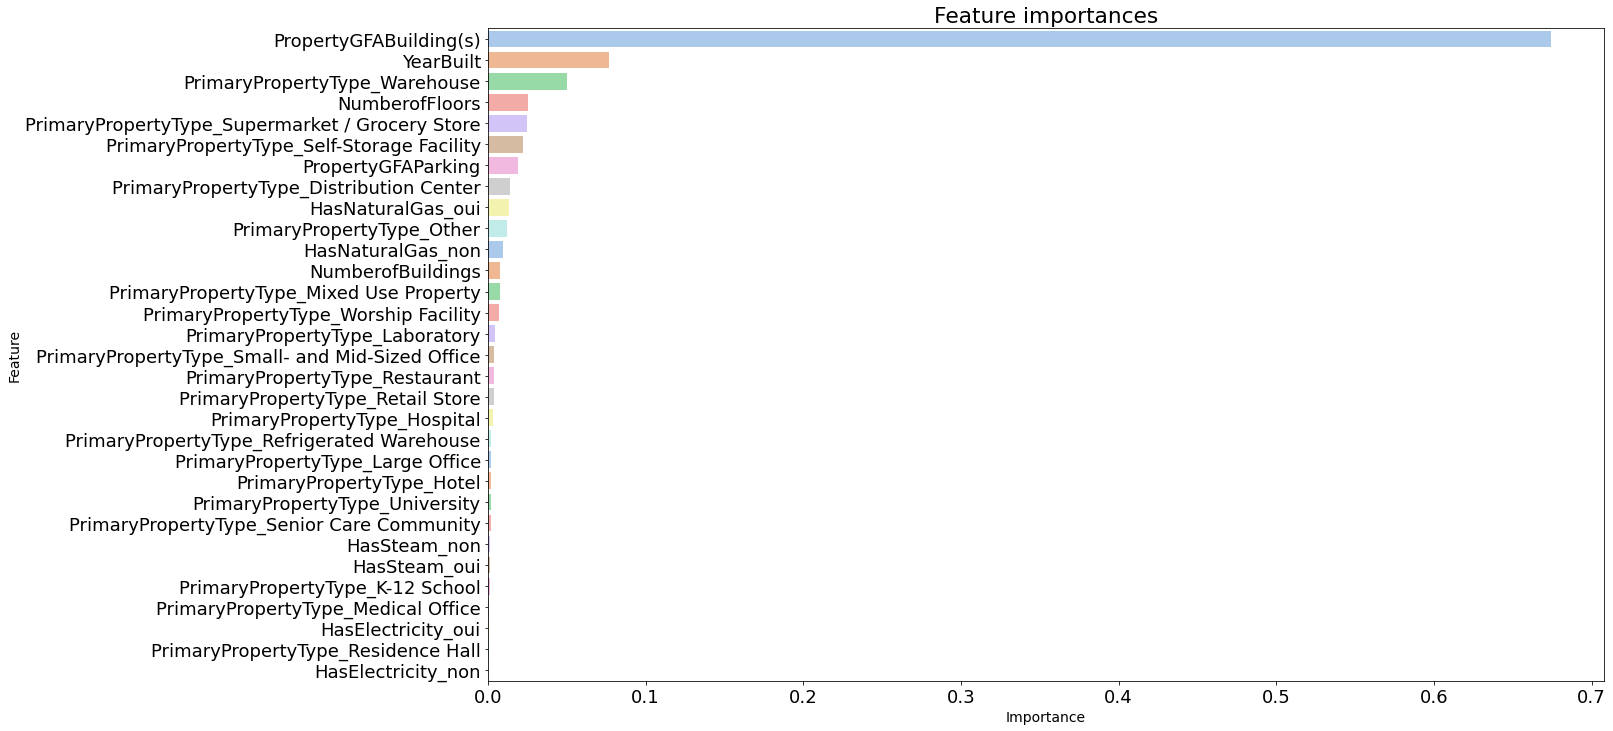

In [112]:
feature_importance(df=data_modelisation_conso2, target_col="SiteEnergyUse(kBtu)")

# Feature engineering avec localisation

In [94]:
data_clean_before_imputation3 = data_clean[["NumberofBuildings", "Latitude","Longitude","NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","TotalGHGEmissions","SiteEnergyUse(kBtu)","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)"]]
data_clean_before_imputation3.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1546 entries, 0 to 3375
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   NumberofBuildings       1546 non-null   float64
 1   Latitude                1546 non-null   float64
 2   Longitude               1546 non-null   float64
 3   NumberofFloors          1546 non-null   int64  
 4   YearBuilt               1546 non-null   int64  
 5   PropertyGFAParking      1546 non-null   int64  
 6   PropertyGFABuilding(s)  1546 non-null   int64  
 7   PrimaryPropertyType     1546 non-null   object 
 8   TotalGHGEmissions       1545 non-null   float64
 9   SiteEnergyUse(kBtu)     1546 non-null   float64
 10  Electricity(kBtu)       1545 non-null   float64
 11  NaturalGas(kBtu)        1546 non-null   float64
 12  SteamUse(kBtu)          1546 non-null   float64
dtypes: float64(8), int64(4), object(1)
memory usage: 169.1+ KB


<div style="background-color:orange; color:dark;"> calcule la distance de chaque bâtiment par rapport au point le plus pollué. Cette distance est ajoutée au DataFrame sous la colonne Distance_Center.<br>
    calcule de la distance de chaque point de données à ce centre-ville supposé. C'est une approche intéressante de l'ingénierie des caractéristiques.
</div>

In [95]:
target_cols = ['TotalGHGEmissions', 'SiteEnergyUse(kBtu)']
data_imputed3 = impute_and_normalize_data(data_clean_before_imputation3, target_cols)

In [96]:
!pip install folium

In [97]:
import folium
from folium.plugins import HeatMap

def find_city_center(df):
    # Création d'une carte avec une heatmap des émissions de gaz à effet de serre (TotalGHGEmissions)
    map_total = folium.Map(location=[df["Latitude"].mean(), df["Longitude"].mean()], zoom_start=11)
    HeatMap(data=df[["Latitude", "Longitude", "TotalGHGEmissions"]], radius=10).add_to(map_total)
    map_total.save("map_total.html")

    # Trouver la localisation la plus polluée dans le DataFrame
    lat_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Latitude"]
    lon_center = df.loc[df["TotalGHGEmissions"].idxmax()]["Longitude"]
    print(f"La localisation la plus polluée se trouve à (latitude, longitude) = ({lat_center:.4f}, {lon_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur la localisation la plus polluée
    map_center = folium.Map(location=[lat_center, lon_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_center)
    map_center.save("map_center.html")

    # Calcul de la distance par rapport à la localisation la plus polluée
    df["Distance_Center"] = np.sqrt((df["Latitude"] - lat_center)**2 + (df["Longitude"] - lon_center)**2)

    # Interprétation de la localisation la plus polluée comme le centre-ville
    df["Distance_CityCenter"] = df["Distance_Center"].apply(lambda x: np.abs(x - df["Distance_Center"].mean()))
    lat_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Latitude"]
    lon_city_center = df.loc[df["Distance_CityCenter"].idxmin()]["Longitude"]
    print(f"Le centre-ville est interprété comme la localisation à (latitude, longitude) = ({lat_city_center:.4f}, {lon_city_center:.4f})")

    # Création d'une carte avec une heatmap centrée sur le centre-ville
    map_city_center = folium.Map(location=[lat_city_center, lon_city_center], zoom_start=13)
    HeatMap(data=df[["Latitude", "Longitude"]], radius=10).add_to(map_city_center)
    map_city_center.save("map_city_center.html")


In [98]:
find_city_center(data_imputed3)

La localisation la plus polluée se trouve à (latitude, longitude) = (47.5349, -122.3179)
Le centre-ville est interprété comme la localisation à (latitude, longitude) = (47.6164, -122.3509)


In [99]:
import folium

# Créez une carte centrée sur le centre-ville
map = folium.Map(location=[47.6164, -122.3509], zoom_start=13)

# Ajoutez chaque point à la carte
for idx, row in data.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.6
    ).add_to(map)

# Affichez la carte
map


In [100]:
data_modelisation_conso3 = data_imputed3[["Distance_CityCenter","NumberofBuildings", "NumberofFloors", "YearBuilt", "PropertyGFAParking", "PropertyGFABuilding(s)", "PrimaryPropertyType","Electricity(kBtu)","NaturalGas(kBtu)","SteamUse(kBtu)",'SiteEnergyUse(kBtu)']]



In [101]:
# Créer des colonnes pour les types d'énergie
data_modelisation_conso3['HasElectricity'] = data_modelisation_conso3['Electricity(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_conso3['HasNaturalGas'] = data_modelisation_conso3['NaturalGas(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_conso3['HasSteam'] = data_modelisation_conso3['SteamUse(kBtu)'].apply(lambda x: "oui" if x > 0 else "non")
data_modelisation_conso3= data_modelisation_conso3.drop(['Electricity(kBtu)', 'NaturalGas(kBtu)', 'SteamUse(kBtu)'], axis=1)


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


### modélisation de la prédiction consommation énergie

In [121]:
grid_search_ridge_fe2_conso, grid_search_lasso_fe2_conso, grid_search_rf_fe2_conso, grid_search_gbr_fe2_conso, X_train_fe2_conso, X_test_fe2_conso, y_train_fe2_conso, y_test_fe2_conso = run_modeling_pipeline(df=data_modelisation_conso3, target_col="SiteEnergyUse(kBtu)", show_graphs=False, random_seed=25, ridge_alpha=[0.1, 1.0, 10.0], lasso_alpha=[0.001, 0.01, 0.1], tol=[1e-3, 1e-4, 1e-5])


Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.965e+16, tolerance: 1.026e+15
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.045e+16, tolerance: 1.078e+15
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.447e+16, tolerance: 3.437e+14
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.965e+16, tolerance: 1.026e+14
Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.045e+16, tolerance: 1.078e+14
Objective did n

Ridge - Best parameters:  {'regressor__alpha': 10.0, 'regressor__tol': 0.001}
Ridge - Best cross-validation score (R2):  0.2546007265765744
Lasso - Best parameters:  {'regressor__alpha': 0.1, 'regressor__tol': 1e-05}
Lasso - Best cross-validation score (R2):  0.04102787968589823
RandomForestRegressor - Best parameters:  {'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}
RandomForestRegressor - Best cross-validation score (R2):  0.5171728996277484
GradientBoostingRegressor - Best parameters:  {'regressor__learning_rate': 0.1, 'regressor__max_depth': 5, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}
GradientBoostingRegressor - Best cross-validation score (R2):  0.5483931331373162


In [122]:
best_score_ridge_fe2_conso = grid_search_ridge_fe2_conso.best_score_
best_score_lasso_fe2_conso = grid_search_lasso_fe2_conso.best_score_
best_score_rf_fe2_conso = grid_search_rf_fe2_conso.best_score_
best_score_gbr_fe2_conso = grid_search_gbr_fe2_conso.best_score_

best_params_ridge_fe2_conso = grid_search_ridge_fe2_conso.best_params_
best_params_lasso_fe2_conso = grid_search_lasso_fe2_conso.best_params_
best_params_rf_fe2_conso = grid_search_rf_fe2_conso.best_params_
best_params_gbr_fe2_conso = grid_search_gbr_fe2_conso.best_params_

# 🔴RESULTS 3 après feature engineering 2 -- CONSO

In [123]:
summary = display_summary([grid_search_ridge_fe2_conso, grid_search_lasso_fe2_conso, grid_search_rf_fe2_conso, grid_search_gbr_fe2_conso], 
                          ['Ridge', 'Lasso', 'RandomForestRegressor', 'GradientBoostingRegressor'], 
                          X_train_fe2_conso, y_train_fe2_conso, X_test_fe2_conso, y_test_fe2_conso)
summary

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.


,Model,Best Params,Best Cross-Val Score (R2),Train Score (R2),Test Score (R2),Train MSE,Test MSE,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Ridge,"{'regressor__alpha': 10.0, 'regressor__tol': 0.001}",0.254601,0.289059,0.238740,657665707679085.125000,916910424704622.875000,25644993.813200,30280528.804904,6771387.659712,7966953.272433
1,Lasso,"{'regressor__alpha': 0.1, 'regressor__tol': 1e-05}",0.041028,0.433023,0.373762,524489689851358.312500,754281124493002.750000,22901739.886990,27464178.933531,8777824.566326,9123144.704049
2,RandomForestRegressor,"{'regressor__ccp_alpha': 1e-06, 'regressor__max_depth': 10, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 3}",0.517173,0.904968,0.425048,87911089412639.781250,692509697644499.750000,9376091.371816,26315578.991246,2533676.959268,5248115.589235
3,GradientBoostingRegressor,"{'regressor__learning_rate': 0.1, 'regressor__max_depth': 5, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 300}",0.548393,0.998677,0.404002,1223450024724.715820,717858774230196.000000,1106096.751973,26792886.634892,761292.881603,5847118.959659


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Lorsqu'on compare les scores R2 de l'ensemble d'entraînement et de l'ensemble de validation, il semble que les modèles de RandomForest et GradientBoosting pourraient être en train de surajuster les données. Le surajustement se produit lorsque le modèle apprend trop bien les détails et le bruit des données d'entraînement, au point où cela nuit à la performance du modèle sur de nouvelles données. C'est ce que l'on peut déduire ici car il y a une grande différence entre les scores R2 d'entraînement et de validation pour ces deux modèles.
<br><br>
les modèles Ridge et Lasso semblent sous-ajuster les données. Le sous-ajustement se produit lorsque le modèle ne peut pas apprendre les tendances sous-jacentes des données. Les faibles scores R2 à la fois sur l'ensemble d'entraînement et sur l'ensemble de validation montrent que ces modèles n'ont pas été capables de capturer la complexité des données.

</p> 

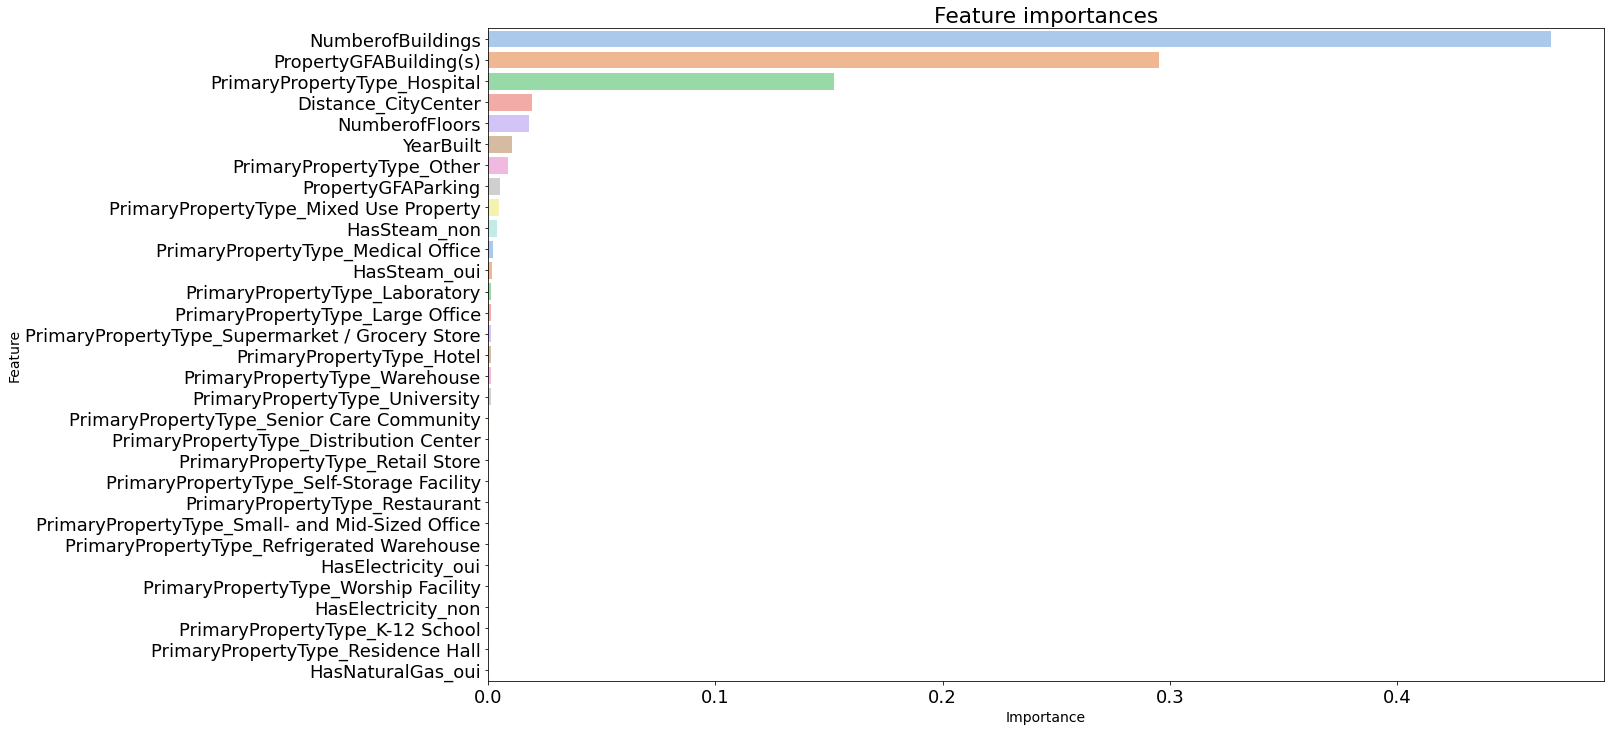

In [124]:
feature_importance(df=data_modelisation_conso3, target_col="SiteEnergyUse(kBtu)")

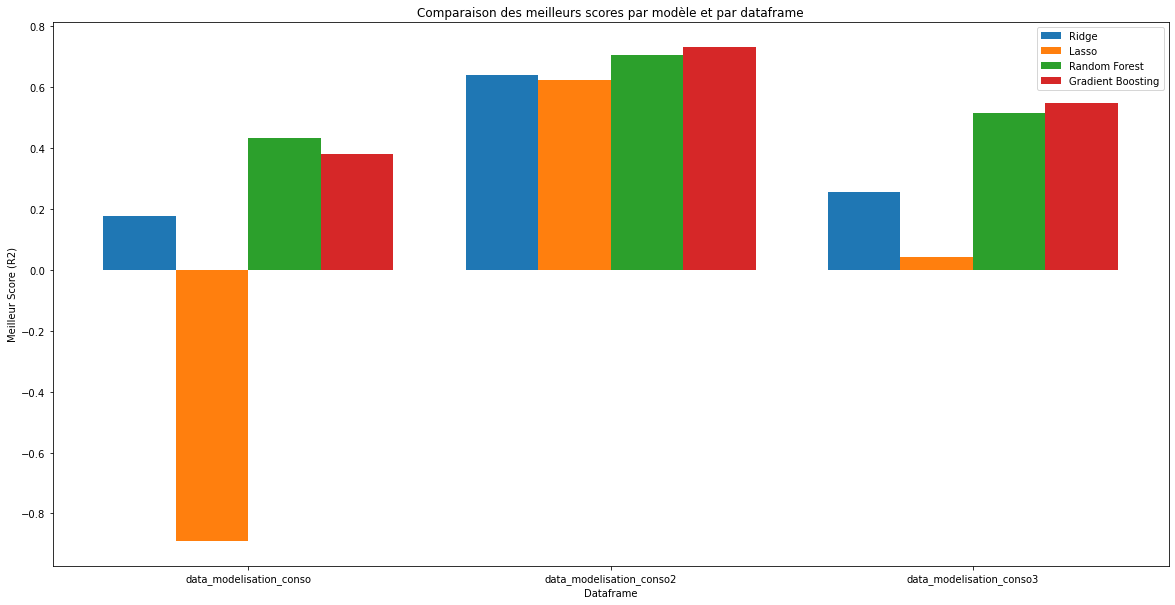

In [125]:
import matplotlib.pyplot as plt
import numpy as np

# Données des scores pour chaque modèle et chaque dataframe
dataframes = ['data_modelisation_conso', 'data_modelisation_conso2', 'data_modelisation_conso3']
models = ['Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']

scores = np.array([
    [best_score_ridge_before_fe_conso, best_score_lasso_before_fe_conso, best_score_rf_before_fe_conso, best_score_gbr_before_fe_conso],
    [best_score_ridge_fe_conso, best_score_lasso_fe_conso, best_score_rf_fe_conso, best_score_gbr_fe_conso],
    [best_score_ridge_fe2_conso, best_score_lasso_fe2_conso, best_score_rf_fe2_conso, best_score_gbr_fe2_conso]
])

# Création du graphique à barres
plt.figure(figsize=(20, 10))
bar_width = 0.2
index = np.arange(len(dataframes))

for i, model in enumerate(models):
    plt.bar(index + i * bar_width, scores[:, i], width=bar_width, label=model)

plt.xlabel('Dataframe')
plt.ylabel('Meilleur Score (R2)')
plt.title('Comparaison des meilleurs scores par modèle et par dataframe')
plt.xticks(index + bar_width * (len(models) - 1) / 2, dataframes)
plt.legend()
plt.show()


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl :</strong> Lorsqu'on compare les scores R2 de l'ensemble d'entraînement et de l'ensemble de validation, il semble que les modèles de RandomForest et GradientBoosting pourraient être en train de surajuster les données. Le surajustement se produit lorsque le modèle apprend trop bien les détails et le bruit des données d'entraînement, au point où cela nuit à la performance du modèle sur de nouvelles données. C'est ce que l'on peut déduire ici car il y a une grande différence entre les scores R2 d'entraînement et de validation pour ces deux modèles.
    <br><br>
    En observant l'indicateur de la qualité de la prédiction (le score R2), on voit que le GradientBoostingRegressor du second modèle (avec le 1er feature engineeering) a un score de test de 0.763498, qui est largement supérieur à ceux obtenus par les modèles du second ensemble.
 <br><br>
De plus, le GradientBoostingRegressor du second modèle présente un Test RMSE (une mesure de l'erreur entre les valeurs prédites et les valeurs réelles) de 0.659765, bien plus faible que ceux du dernier modèle (2e feature engineering), indiquant des prédictions plus précises.
 <br><br>
Enfin, l'erreur moyenne absolue (MAE) pour le GradientBoostingRegressor du 2nd modèle est de 0.494479, qui est également bien inférieure à toutes les erreurs moyennes absolues (MAE) du dernier modèle.
 <br><br>
Le second modèle est donc le meilleur pour la consommation.
</p> 